# AI-Based Student Performance Prediction and Analysis System
**Jupyter Notebook Project**

**Goal:** Explore student-related factors and build regression models to predict `Exam_Score`.

**Workflow:** Load data → inspect/clean → EDA → preprocess → train models → evaluate → feature importance → predict for a new student.

> Run cells from top to bottom. Keep `StudentPerformanceFactors.csv` in the same folder as this notebook.

## 1. Import libraries

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

## 2. Load the dataset

In [2]:
# The CSV should be in the same folder as this notebook.
df = pd.read_csv("StudentPerformanceFactors.csv")

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (6607, 20)


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70


## 3. Inspect and clean the data

In [3]:
print("Column names:")
print(df.columns.tolist())

print("\\nData types and non-null counts:")
df.info()

print("\\nMissing values per column:")
display(df.isnull().sum().sort_values(ascending=False))

print("\\nDuplicate rows:", df.duplicated().sum())

# Remove exact duplicate rows, if any.
df = df.drop_duplicates().copy()

# Ensure the target exists.
if "Exam_Score" not in df.columns:
    raise ValueError("Target column 'Exam_Score' was not found. Check the dataset column names.")

display(df.describe(include="all").T)

Column names:
['Hours_Studied', 'Attendance', 'Parental_Involvement', 'Access_to_Resources', 'Extracurricular_Activities', 'Sleep_Hours', 'Previous_Scores', 'Motivation_Level', 'Internet_Access', 'Tutoring_Sessions', 'Family_Income', 'Teacher_Quality', 'School_Type', 'Peer_Influence', 'Physical_Activity', 'Learning_Disabilities', 'Parental_Education_Level', 'Distance_from_Home', 'Gender', 'Exam_Score']
\nData types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6607 entries, 0 to 6606
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype 
---  ------                      --------------  ----- 
 0   Hours_Studied               6607 non-null   int64 
 1   Attendance                  6607 non-null   int64 
 2   Parental_Involvement        6607 non-null   object
 3   Access_to_Resources         6607 non-null   object
 4   Extracurricular_Activities  6607 non-null   object
 5   Sleep_Hours                 6607 non-null   int64 
 6   

Parental_Education_Level      90
Teacher_Quality               78
Distance_from_Home            67
Hours_Studied                  0
Attendance                     0
Gender                         0
Learning_Disabilities          0
Physical_Activity              0
Peer_Influence                 0
School_Type                    0
Family_Income                  0
Tutoring_Sessions              0
Internet_Access                0
Motivation_Level               0
Previous_Scores                0
Sleep_Hours                    0
Extracurricular_Activities     0
Access_to_Resources            0
Parental_Involvement           0
Exam_Score                     0
dtype: int64

\nDuplicate rows: 0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Hours_Studied,6607.0,NaN,NaN,NaN,19.975329,5.990594,1.0,16.0,20.0,24.0,44.0
Attendance,6607.0,NaN,NaN,NaN,79.977448,11.547475,60.0,70.0,80.0,90.0,100.0
Parental_Involvement,6607,3,Medium,3362,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Access_to_Resources,6607,3,Medium,3319,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Extracurricular_Activities,6607,2,Yes,3938,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sleep_Hours,6607.0,NaN,NaN,NaN,7.02906,1.46812,4.0,6.0,7.0,8.0,10.0
Previous_Scores,6607.0,NaN,NaN,NaN,75.070531,14.399784,50.0,63.0,75.0,88.0,100.0
Motivation_Level,6607,3,Medium,3351,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Internet_Access,6607,2,Yes,6108,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Tutoring_Sessions,6607.0,NaN,NaN,NaN,1.493719,1.23057,0.0,1.0,1.0,2.0,8.0


## 4. Exploratory Data Analysis (EDA)

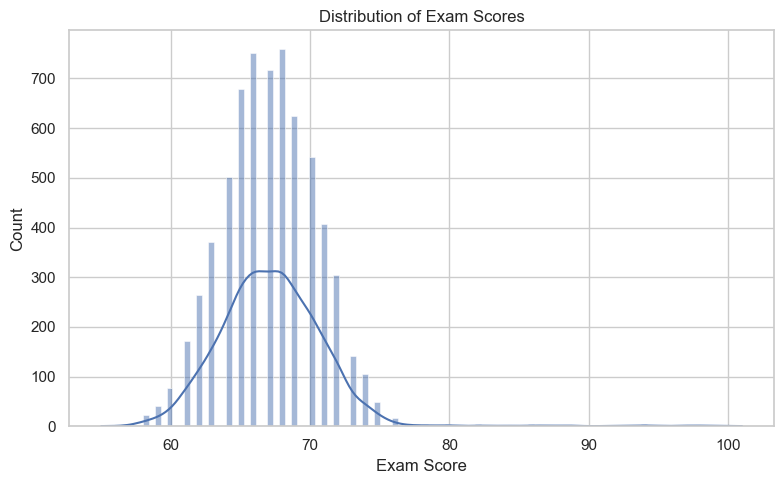

In [4]:
plt.figure(figsize=(8, 5))
sns.histplot(df["Exam_Score"], kde=True)
plt.title("Distribution of Exam Scores")
plt.xlabel("Exam Score")
plt.tight_layout()
plt.show()

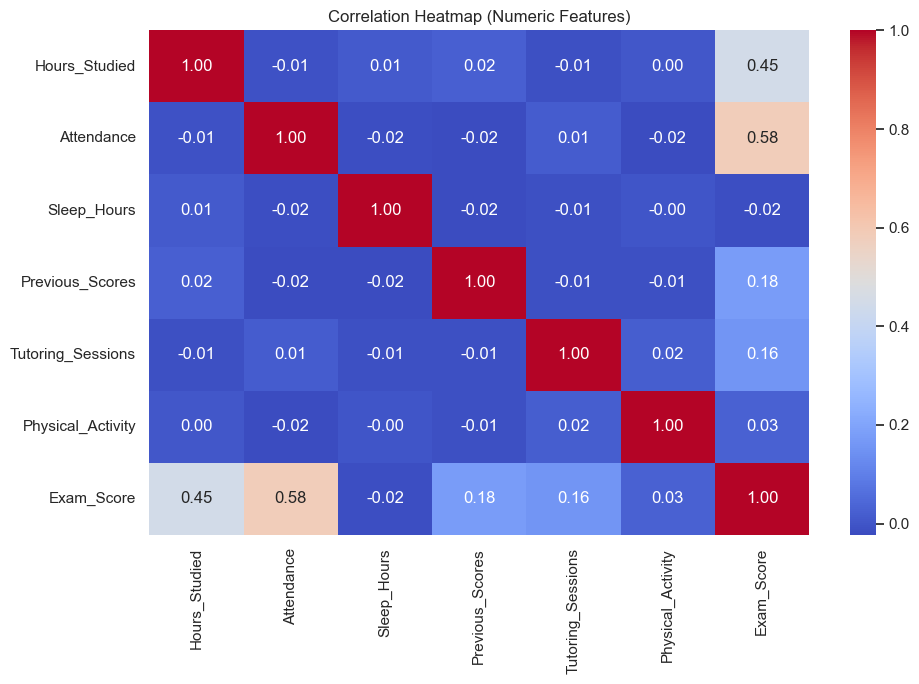

In [5]:
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()

plt.figure(figsize=(10, 7))
sns.heatmap(df[numeric_cols].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap (Numeric Features)")
plt.tight_layout()
plt.show()

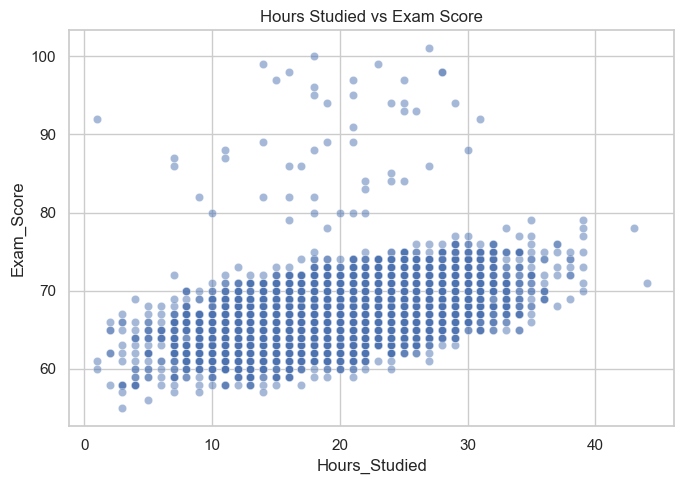

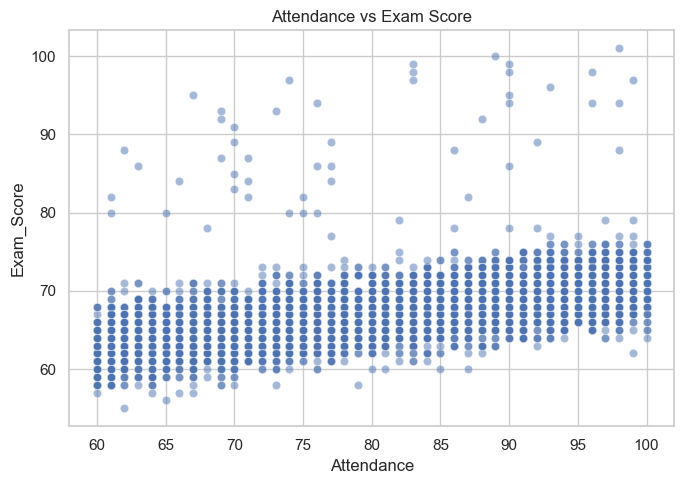

In [6]:
if "Hours_Studied" in df.columns:
    plt.figure(figsize=(7, 5))
    sns.scatterplot(data=df, x="Hours_Studied", y="Exam_Score", alpha=0.5)
    plt.title("Hours Studied vs Exam Score")
    plt.tight_layout()
    plt.show()

if "Attendance" in df.columns:
    plt.figure(figsize=(7, 5))
    sns.scatterplot(data=df, x="Attendance", y="Exam_Score", alpha=0.5)
    plt.title("Attendance vs Exam Score")
    plt.tight_layout()
    plt.show()

## 5. Prepare features and target

In [7]:
# Target variable
y = df["Exam_Score"].copy()

# Remove the target from the input features.
X = df.drop(columns=["Exam_Score"]).copy()

# Detect numeric and categorical columns automatically.
numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)

# Numeric columns: fill missing values with median.
# Categorical columns: fill missing values with most frequent value, then one-hot encode.
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])

Numeric features: ['Hours_Studied', 'Attendance', 'Sleep_Hours', 'Previous_Scores', 'Tutoring_Sessions', 'Physical_Activity']
Categorical features: ['Parental_Involvement', 'Access_to_Resources', 'Extracurricular_Activities', 'Motivation_Level', 'Internet_Access', 'Family_Income', 'Teacher_Quality', 'School_Type', 'Peer_Influence', 'Learning_Disabilities', 'Parental_Education_Level', 'Distance_from_Home', 'Gender']
Training rows: 5285
Testing rows: 1322


## 6. Train two regression models

In [8]:
models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    )
}

trained_models = {}
results = []

for name, estimator in models.items():
    pipe = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", estimator)
    ])
    pipe.fit(X_train, y_train)
    predictions = pipe.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    trained_models[name] = pipe
    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2 Score": r2
    })

results_df = pd.DataFrame(results).sort_values("RMSE")
display(results_df.round(3))

,Model,MAE,RMSE,R2 Score
0,Linear Regression,0.452,1.804,0.77
1,Random Forest,1.080,2.159,0.67


## 7. Compare actual and predicted scores

Best model by RMSE: Linear Regression


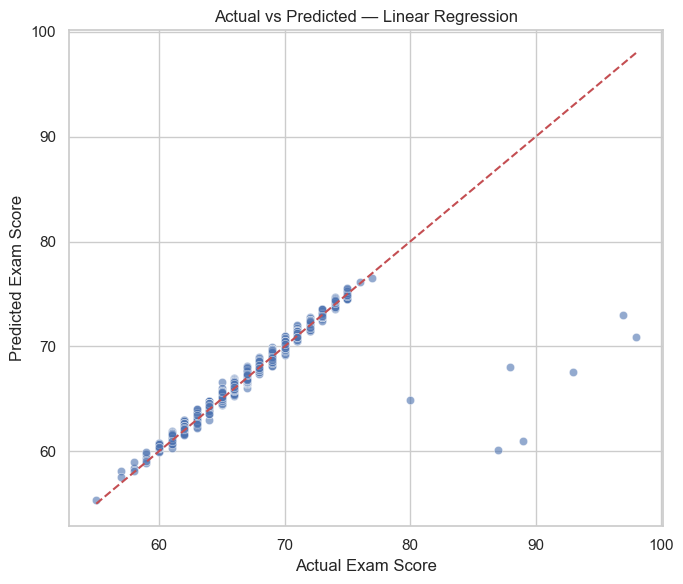

In [9]:
best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]
best_predictions = best_model.predict(X_test)

print("Best model by RMSE:", best_model_name)

plt.figure(figsize=(7, 6))
sns.scatterplot(x=y_test, y=best_predictions, alpha=0.6)
min_val = min(y_test.min(), best_predictions.min())
max_val = max(y_test.max(), best_predictions.max())
plt.plot([min_val, max_val], [min_val, max_val], "r--")
plt.xlabel("Actual Exam Score")
plt.ylabel("Predicted Exam Score")
plt.title(f"Actual vs Predicted — {best_model_name}")
plt.tight_layout()
plt.show()

## 8. Feature importance (Random Forest)

,Feature,Importance
1,num__Attendance,0.374594
0,num__Hours_Studied,0.240574
3,num__Previous_Scores,0.085019
4,num__Tutoring_Sessions,0.033134
5,num__Physical_Activity,0.024561
2,num__Sleep_Hours,0.024064
9,cat__Access_to_Resources_High,0.019144
6,cat__Parental_Involvement_High,0.018028
7,cat__Parental_Involvement_Low,0.014129
10,cat__Access_to_Resources_Low,0.011329


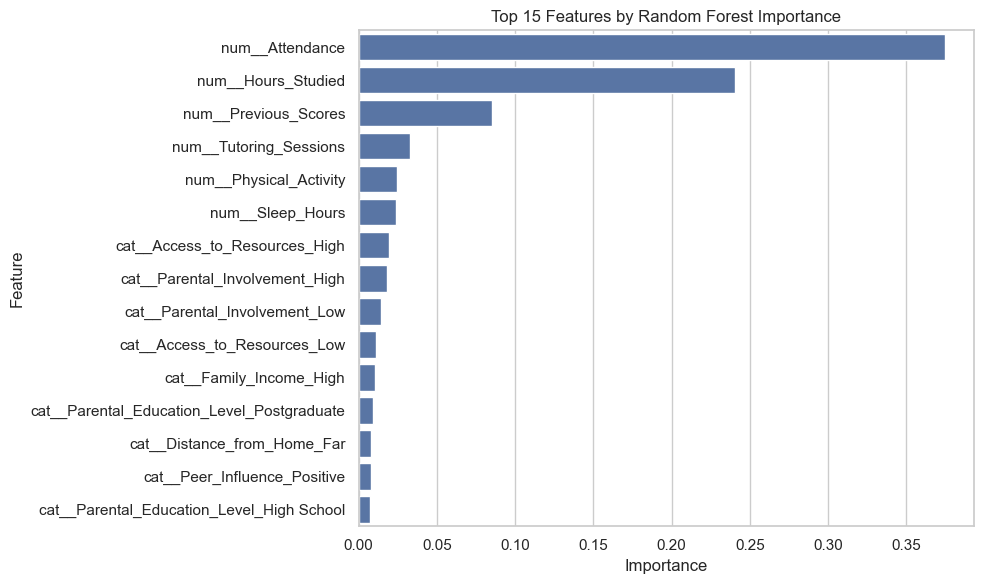

In [10]:
rf_pipe = trained_models["Random Forest"]
rf_model = rf_pipe.named_steps["model"]
feature_names = rf_pipe.named_steps["preprocessor"].get_feature_names_out()

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_model.feature_importances_
}).sort_values("Importance", ascending=False).head(15)

display(importance_df)

plt.figure(figsize=(10, 6))
sns.barplot(data=importance_df, x="Importance", y="Feature")
plt.title("Top 15 Features by Random Forest Importance")
plt.tight_layout()
plt.show()

## 9. Predict a score for a new student

In [11]:
# Example: use a real row from the dataset as a template, then edit values.
new_student = X.iloc[[0]].copy()

# Example edits, only if these columns exist:
if "Hours_Studied" in new_student.columns:
    new_student.loc[:, "Hours_Studied"] = 5
if "Attendance" in new_student.columns:
    new_student.loc[:, "Attendance"] = 90
if "Sleep_Hours" in new_student.columns:
    new_student.loc[:, "Sleep_Hours"] = 8
if "Tutoring_Sessions" in new_student.columns:
    new_student.loc[:, "Tutoring_Sessions"] = 2

display(new_student)

predicted_score = best_model.predict(new_student)[0]
print(f"Predicted exam score: {predicted_score:.2f}")

,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender
0,5,90,Low,High,No,8,73,Low,Yes,2,Low,Medium,Public,Positive,3,No,High School,Near,Male


Predicted exam score: 64.04


## 10. Conclusion (complete after running the notebook)

After running the notebook, summarize:
- Which model performed best based on RMSE and MAE.
- The model's R² score on the test set.
- Which features had the highest importance in the Random Forest model.
- Limitations: predictions are estimates based on this dataset and do not prove that a feature causes a score change.

**Important:** Do not claim a model is highly accurate until you have run the notebook and reviewed the evaluation metrics.

In [12]:
import joblib

# Aapka trained pipeline/model aur preprocessor save karein
joblib.dump(best_model, "student_model.pkl")

['student_model.pkl']

In [13]:
%%writefile app.py
import streamlit as st
import pandas as pd
import joblib

# Streamlit UI Configuration
st.set_page_config(page_title="Student Performance Predictor", layout="centered")
st.title("🎓 Student Performance Prediction System")
st.write("Student ki details enter karein aur predicted exam score dekhein.")

# Model Load karein
model = joblib.load('student_model.pkl')

# User Inputs Form
with st.form("prediction_form"):
    st.subheader("Student Details")
    
    col1, col2 = st.columns(2)
    
    with col1:
        hours_studied = st.number_input("Hours Studied", min_value=0, max_value=100, value=20)
        attendance = st.number_input("Attendance (%)", min_value=0, max_value=100, value=80)
        sleep_hours = st.number_input("Sleep Hours", min_value=0, max_value=24, value=7)
        previous_scores = st.number_input("Previous Scores", min_value=0, max_value=100, value=75)
        tutoring_sessions = st.number_input("Tutoring Sessions", min_value=0, max_value=10, value=1)
        physical_activity = st.number_input("Physical Activity (hrs/wk)", min_value=0, max_value=10, value=3)
        
    with col2:
        parental_involvement = st.selectbox("Parental Involvement", ["Low", "Medium", "High"])
        access_to_resources = st.selectbox("Access to Resources", ["Low", "Medium", "High"])
        extracurricular = st.selectbox("Extracurricular Activities", ["Yes", "No"])
        motivation_level = st.selectbox("Motivation Level", ["Low", "Medium", "High"])
        internet_access = st.selectbox("Internet Access", ["Yes", "No"])
        family_income = st.selectbox("Family Income", ["Low", "Medium", "High"])

    st.subheader("Additional Info")
    col3, col4 = st.columns(2)
    
    with col3:
        teacher_quality = st.selectbox("Teacher Quality", ["Low", "Medium", "High"])
        school_type = st.selectbox("School Type", ["Public", "Private"])
        peer_influence = st.selectbox("Peer Influence", ["Positive", "Neutral", "Negative"])
        
    with col4:
        learning_disabilities = st.selectbox("Learning Disabilities", ["Yes", "No"])
        parental_education = st.selectbox("Parental Education Level", ["High School", "College", "Postgraduate"])
        distance_from_home = st.selectbox("Distance from Home", ["Near", "Moderate", "Far"])
        gender = st.selectbox("Gender", ["Male", "Female"])

    submit = st.form_submit_button("Predict Exam Score")

if submit:
    input_data = pd.DataFrame([{
        'Hours_Studied': hours_studied,
        'Attendance': attendance,
        'Parental_Involvement': parental_involvement,
        'Access_to_Resources': access_to_resources,
        'Extracurricular_Activities': extracurricular,
        'Sleep_Hours': sleep_hours,
        'Previous_Scores': previous_scores,
        'Motivation_Level': motivation_level,
        'Internet_Access': internet_access,
        'Tutoring_Sessions': tutoring_sessions,
        'Family_Income': family_income,
        'Teacher_Quality': teacher_quality,
        'School_Type': school_type,
        'Peer_Influence': peer_influence,
        'Physical_Activity': physical_activity,
        'Learning_Disabilities': learning_disabilities,
        'Parental_Education_Level': parental_education,
        'Distance_from_Home': distance_from_home,
        'Gender': gender
    }])

    prediction = model.predict(input_data)[0]
    st.success(f"🎯 **Predicted Exam Score:** {prediction:.2f}")

Writing app.py


In [ ]:
git init